# PayWatch: SHAP explanations

The API returns the top reasons for each decision from LightGBM's exact tree SHAP values (`pred_contrib`). This notebook checks that the contributions are exact and shows which features and families drive the shipped LightGBM model. Individual rows are never shown, only feature names and contribution sizes.

In [1]:
import glob, json, os, re, shutil, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve
warnings.filterwarnings("ignore")
%matplotlib inline
pd.set_option("display.width", 140)
T0 = time.time()
DEVICE = "cuda" if shutil.which("nvidia-smi") else "cpu"
find = lambda p: sorted(glob.glob(p, recursive=True))
sys.path.insert(0, os.path.dirname(find("/kaggle/input/**/upi_fingerprint.py")[0]))
sys.path.insert(0, os.path.dirname(find("/kaggle/input/**/evasion.py")[0]))
import engineer
from entity_history import BASE_KEYS
RAW = os.path.dirname(find("/kaggle/input/**/train_transaction.csv")[0])
import lightgbm as lgb
MODEL_DIR = os.path.dirname(find("/kaggle/input/**/lgbm_seed42.txt")[0])      # production LightGBM model directory (models/compact)
SPEC = json.load(open(f"{MODEL_DIR}/serving_spec.json"))
COLS = SPEC["features"]
SHIPPED = sorted(glob.glob(f"{MODEL_DIR}/lgbm_seed*.txt"))
ISO = json.load(open(f"{MODEL_DIR}/isotonic.json"))
raw = engineer.load_raw(RAW)
base = engineer.build_base(raw.copy(), lags=(7,), decay_lags=(), velocity=False, key_names=BASE_KEYS)
(tr, va, te), art = engineer.finalize(base, d_mode="anchor", return_artifacts=True)
(X_tr, y_tr, t_tr), (X_va, y_va, t_va), (X_te, y_te, t_te) = tr, va, te
UPI_B = {"amount_vs_7day_avg_ratio", "merchant_category_entropy", "hour_deviation_from_user_mean",
         "days_since_last_large_txn", "is_new_merchant", "is_p2p"}


def family(f):
    if f.startswith("h7_"):
        return "entity fraud history"
    if f.startswith("uid_") or f in UPI_B:
        return "UPI behaviour"
    if f.endswith("_freq"):
        return "frequency encoding"
    if re.fullmatch(r"D\d+", f):
        return "time deltas (D)"
    if re.fullmatch(r"V\d+", f):
        return "Vesta V"
    if f.startswith("id_") or f.startswith("Device"):
        return "identity / device"
    if re.fullmatch(r"[CM]\d+", f):
        return "counts / match flags (C, M)"
    return "raw transaction"


def recall_at_fpr(y, p, f):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.interp(f, fpr, tpr))


def op_threshold(score, y, target, n_min=100):
    order = np.argsort(-score)
    tp = np.cumsum(y[order])
    n = np.arange(1, len(y) + 1)
    ok = np.where((tp / n >= target) & (n >= n_min))[0]
    return float(score[order][ok.max()]) if len(ok) else None


def shipped_boosters():
    return [lgb.Booster(model_file=p) for p in SHIPPED]


def ensemble_score(boosters, X):
    X = np.asarray(X, dtype=np.float32)
    return np.mean([b.predict(X) for b in boosters], axis=0)


print(f"device: {DEVICE} | pipeline built in {(time.time() - T0) / 60:.1f} min | train {X_tr.shape}, val {X_va.shape}, test {X_te.shape} | compact features: {len(COLS)}")

device: cpu | pipeline built in 1.0 min | train (413378, 452), val (88581, 452), test (88581, 452) | compact features: 120


## 1. Exactness: contributions must sum to the model output

In [2]:
ship = shipped_boosters()
rng = np.random.default_rng(0)
idx = np.sort(rng.choice(len(X_te), 5000, replace=False))
Xs = pd.DataFrame(X_te[COLS].to_numpy(dtype=np.float32)[idx], columns=COLS)
Xv = Xs.to_numpy(dtype=np.float32)
contribs = [b.predict(Xv, pred_contrib=True) for b in ship]
margins = [b.predict(Xv, raw_score=True) for b in ship]
err = max(float(np.abs(c.sum(axis=1) - m_).max()) for c, m_ in zip(contribs, margins))
print(f"max |sum of SHAP values + bias - model margin| over 3 models x 5000 rows: {err:.2e}")
assert err < 1e-3
shap = np.mean([c[:, :-1] for c in contribs], axis=0)

max |sum of SHAP values + bias - model margin| over 3 models x 5000 rows: 4.26e-10


## 2. What drives the model

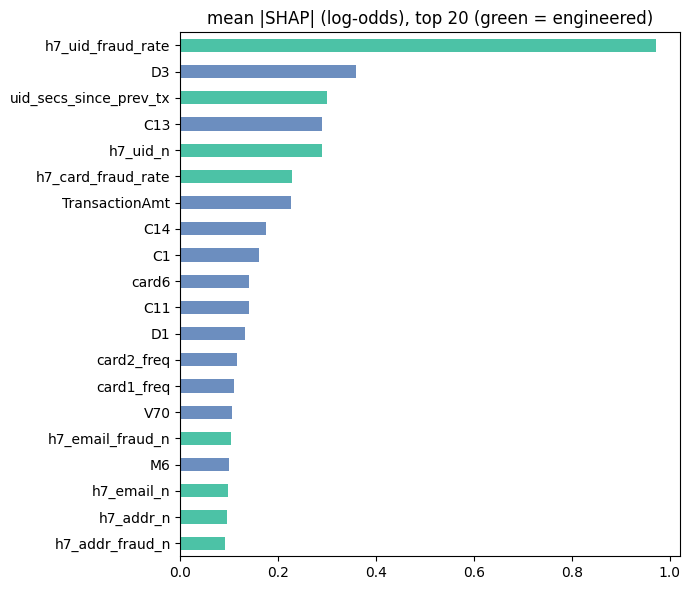

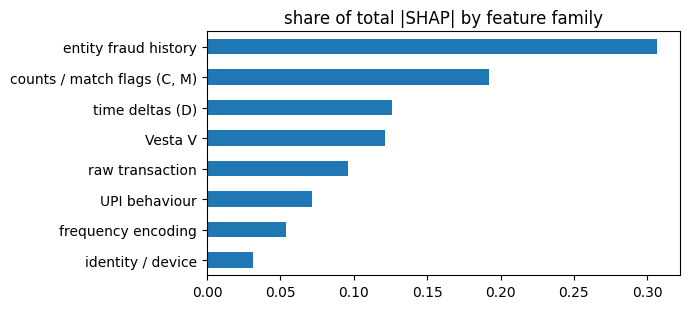

,share
entity fraud history,0.307
"counts / match flags (C, M)",0.192
time deltas (D),0.126
Vesta V,0.121
raw transaction,0.096
UPI behaviour,0.072
frequency encoding,0.054
identity / device,0.031


In [3]:
imp = pd.Series(np.abs(shap).mean(axis=0), index=COLS).sort_values(ascending=False)
colors = ["#4cc2a6" if family(f) in ("entity fraud history", "UPI behaviour") else "#6c8ebf" for f in imp.head(20).index]
imp.head(20)[::-1].plot(kind="barh", figsize=(7, 6), color=colors[::-1], title="mean |SHAP| (log-odds), top 20 (green = engineered)")
plt.tight_layout(); plt.show()
fam = imp.groupby([family(f) for f in imp.index]).sum().sort_values(ascending=False)
(fam / fam.sum()).plot(kind="barh", figsize=(7, 3.2), title="share of total |SHAP| by feature family"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()
display((fam / fam.sum()).round(3).to_frame("share"))

## 3. Direction of effect

Correlation between a feature's value and its SHAP value tells whether higher values push towards fraud (+) or away (-) on this sample.

In [4]:
vals = Xs.to_numpy()
rows = []
for c in imp.head(15).index:
    j = COLS.index(c)
    v, s = vals[:, j], shap[:, j]
    r = np.corrcoef(v, s)[0, 1] if v.std() > 0 and s.std() > 0 else np.nan
    rows.append({"feature": c, "family": family(c), "mean_abs_shap": round(float(np.abs(s).mean()), 4), "corr(value, shap)": round(float(r), 2)})
display(pd.DataFrame(rows))

,feature,family,mean_abs_shap,"corr(value, shap)"
0,h7_uid_fraud_rate,entity fraud history,0.9725,0.57
1,D3,time deltas (D),0.3599,-0.92
2,uid_secs_since_prev_tx,UPI behaviour,0.3002,-0.53
3,C13,"counts / match flags (C, M)",0.2904,-0.50
4,h7_uid_n,entity fraud history,0.2890,-0.43
5,h7_card_fraud_rate,entity fraud history,0.2274,0.80
6,TransactionAmt,raw transaction,0.2252,0.45
7,C14,"counts / match flags (C, M)",0.1753,-0.31
8,C1,"counts / match flags (C, M)",0.1608,0.47
9,card6,raw transaction,0.1395,-0.26


## 4. Reason lists the way the API shows them

For three confidently flagged test frauds, the top positive contributions (feature name and SHAP size only).

In [5]:
score = ensemble_score(ship, Xs)
flagged = np.where((y_te[idx] == 1) & (score >= np.percentile(score, 98)))[0][:3]
for k, i in enumerate(flagged, 1):
    order = np.argsort(-shap[i])[:5]
    print(f"flagged fraud {k}: " + ", ".join(f"{COLS[j]} (+{shap[i, j]:.2f})" for j in order))
print("\nthe API additionally turns these into plain-language text per feature family")

flagged fraud 1: V257 (+1.95), C1 (+1.18), C13 (+0.73), C11 (+0.67), h7_uid_fraud_rate (+0.66)
flagged fraud 2: h7_uid_fraud_rate (+5.70), h7_uid_fraud_n (+1.69), h7_card_fraud_rate (+0.61), merchant_category_entropy (+0.29), V317 (+0.26)
flagged fraud 3: C13 (+1.01), C1 (+0.91), V187 (+0.83), h7_uid_fraud_rate (+0.73), V201 (+0.59)

the API additionally turns these into plain-language text per feature family


## 5. Can the API explain with one seed instead of three?

Tree SHAP on three 529-tree models is the slowest part of a request. If one seed's attributions give the same top reasons as the three-seed average, the API can explain from one seed (a third of the cost) without changing what it tells users.

In [6]:
one = contribs[0][:, :-1]
three = shap
top = lambda M: np.argsort(-np.abs(M), axis=1)[:, :5]
t1, t3 = top(one), top(three)
overlap = np.mean([len(set(a) & set(b)) / 5 for a, b in zip(t1, t3)])
same_set = np.mean([set(a) == set(b) for a, b in zip(t1, t3)])
same_first = np.mean(t1[:, 0] == t3[:, 0])
print(f"top-5 reasons, seed 42 alone vs 3-seed average, {len(idx)} rows: mean overlap {overlap:.3f}, identical set {same_set:.1%}, same top-1 reason {same_first:.1%}")
import time as _t
rows = Xv[:300]
for label, bs in (("1 seed", ship[:1]), ("3 seeds", ship)):
    t0 = _t.perf_counter()
    for r in rows:
        for b in bs:
            b.predict(r.reshape(1, -1), pred_contrib=True)
    print(f"{label}: {(_t.perf_counter() - t0) / len(rows) * 1000:.1f} ms per explanation (single row, this machine)")

top-5 reasons, seed 42 alone vs 3-seed average, 5000 rows: mean overlap 0.870, identical set 44.3%, same top-1 reason 94.3%


1 seed: 72.1 ms per explanation (single row, this machine)


3 seeds: 214.4 ms per explanation (single row, this machine)


## Takeaways

- SHAP values add up exactly to the model output, so the reasons shown to users are the model's real arithmetic, not an approximation.
- Engineered history and behaviour features account for a large share of total attribution; they are also the features a fresh identity resets, which is the evasion risk tested in `04b`.